# Modelo de referencia (*baseline*) para HAR con sEMG
## Proyecto Integrador — Avance 3

**Equipo 1**

| Nombre | Matrícula |
|---|---|
| Isaura Yutsil Flores Escamilla | A01796552 |
| Paola Alejandra León Guarneros | A01796230 |
| Dylan Ulises Quiroz Hernández  | A01796578 |

**Fecha:** 17 de octubre de 2026

> **Objetivo:** construir modelos simples que sirvan de **referencia** para el problema de reconocer siete actividades de manejo manual de cargas (`N`, `LF`, `K`, `PT`, `LT`, `W`, `PF`) a partir de las 8 envolventes sEMG. Con ellos se responde si el problema es viable, cuánto se puede lograr con métodos sencillos y qué tanto deben superarlos los modelos complejos (CPC–xLSTM) que el equipo ya exploró.

### Cómo responde este notebook a la rúbrica

| Pregunta | Sección |
| :--- | :--- |
| ¿Cuál es la métrica adecuada para el problema? | 2 |
| ¿Qué algoritmo se puede usar como baseline? | 3–4 |
| ¿El modelo está sub/sobreajustando? ¿Cómo corregirlo? | 5 |
| ¿Se puede determinar la importancia de las características? ¿Hay características irrelevantes? | 6 |
| ¿Cuál debería ser el desempeño mínimo? | 7 |
| Conclusiones | 8 |

### Punto de partida: lo que ya probó el equipo

Las ramas del proyecto aplicaron **Contrastive Predictive Coding (CPC)**: un modelo que aprende a resumir la señal sin etiquetas y luego clasifica. Su mejor versión (CPC con un autorregresivo sLSTM, ajuste fino, 12 Hz) obtuvo un **F1 macro de 0.46 ± 0.05** al evaluarse con sujetos nuevos (*leave-one-subject-out*, notebook `06_CPC_LOSO`). Un baseline responde una pregunta que esos experimentos no respondían: **¿cuánto de ese resultado se logra sin aprendizaje profundo?**

# 1. Configuración y datos

Se usa la exportación del **avance 2** a 12 Hz (`notebooks/_cache/avance2/fs12/`), la misma que usó el LOSO de CPC. Así ambos modelos ven **exactamente las mismas ventanas**:

- **Ventanas:** 4 s que terminan cada 0.5 s.
- **Etiqueta:** la del **instante final** de cada ventana.
- **Características:** las **202 características** de dominio calculadas en el avance 2 (nivel, dispersión, dinámica, espectro y coactivación de los 8 canales, en %MVC).

**Sujetos:** se trabaja con los 12 sujetos de desarrollo (1–12). Los sujetos **13 y 14 (prueba) no se usan**: quedan reservados para la evaluación final del modelo elegido.

**Variables de contexto:** la tarea, la carga y la condición **no** se usan como predictores. El avance 2 mostró que son atajos del protocolo (por ejemplo, los ensayos isocinéticos sólo tienen 4 de las 7 clases) y no información de la señal.

In [1]:
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, SplineTransformer, StandardScaler

SEED = 0
TARGET_FS = 12                              # misma frecuencia que el LOSO de CPC
DEV_SUBJECTS = list(range(1, 13))           # sujetos de desarrollo; 13 y 14 (prueba) no se usan
QUICK = False                               # True = corrida rápida de prueba (menos datos y pliegues)

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EXPORT_DIR = REPO_DIR / "notebooks" / "_cache" / "avance2" / f"fs{TARGET_FS}"
CPC_LOSO_CSV = REPO_DIR / "notebooks" / "_cache" / f"cpc06_loso_fs{TARGET_FS}_resultados.csv"
assert (EXPORT_DIR / "metadata.json").exists(), f"Falta {EXPORT_DIR}: ejecutar avance2 con TARGET_FS = {TARGET_FS} y export_artifacts()"

FOLD_SUBJECTS = DEV_SUBJECTS[:3] if QUICK else DEV_SUBJECTS
TRAIN_CAP = 6_000 if QUICK else None        # en QUICK se entrena con una submuestra
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

meta = json.loads((EXPORT_DIR / "metadata.json").read_text())
LABELS = meta["label_order"]
FEATURES = meta["feature_columns"]
LABEL_COLORS = {"N": "#9e9e9e", "LF": "#1f77b4", "K": "#ff7f0e", "PT": "#2ca02c", "LT": "#d62728", "W": "#9467bd", "PF": "#8c564b"}

table = pd.read_csv(EXPORT_DIR / "features.csv.gz")
dev = table[table["subject"].isin(DEV_SUBJECTS)].reset_index(drop=True)
X = dev[FEATURES].to_numpy(dtype=np.float32)       # 202 características por ventana
y = dev["target"].to_numpy()                       # clase de la ventana (0-6)
groups = dev["subject"].to_numpy()                 # sujeto de cada ventana (define los pliegues)

print(f"{len(dev):,} ventanas de {len(DEV_SUBJECTS)} sujetos | {len(FEATURES)} características | {TARGET_FS} Hz | QUICK = {QUICK}")

53,223 ventanas de 12 sujetos | 202 características | 12 Hz | QUICK = False


# 2. ¿Cuál es la métrica adecuada?

**El problema de negocio.** El dataset proviene de tareas de **manejo manual de cargas**. Un sistema así sirve para monitorear riesgo ergonómico: cuántas veces y cómo levanta, sostiene, transporta y coloca carga una persona. Para ese uso, **todas las actividades importan**, y en particular las de esfuerzo (`LF`, `LT`, `K`, `W`), no sólo distinguir reposo de actividad.

**Las clases están desbalanceadas:** `N` (postura neutral) es casi la mitad de las ventanas.

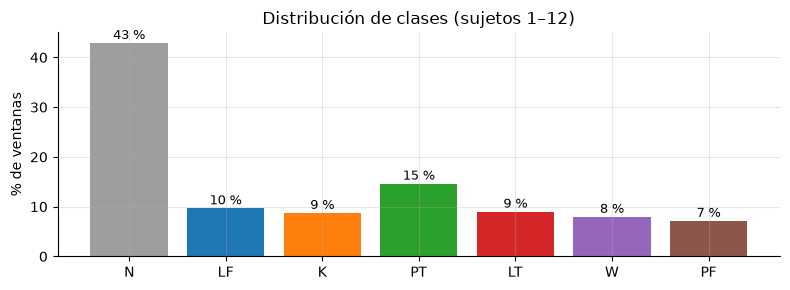

In [2]:
counts = pd.Series(y).map(dict(enumerate(LABELS))).value_counts().reindex(LABELS)
share = counts / counts.sum()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(LABELS, share * 100, color=[LABEL_COLORS[l] for l in LABELS])
for i, v in enumerate(share * 100):
    ax.text(i, v + 0.8, f"{v:.0f} %", ha="center", fontsize=9)
ax.set(ylabel="% de ventanas", title="Distribución de clases (sujetos 1–12)")
plt.tight_layout()
plt.show()

**Por qué no la *accuracy*.** Con este desbalance, un "modelo" que siempre responde `N` acierta ~43 % de las ventanas sin reconocer ninguna actividad. La *accuracy* premia acertar la clase grande e ignora las demás (en la sección 4 se ve con números).

**Métrica principal: F1 macro.**

- Para cada clase, el **F1** combina:
  - la **precisión** (de las veces que el modelo dijo "`LF`", cuántas eran `LF`);
  - el **recall** (de las ventanas que eran `LF`, cuántas encontró).

  Es su media armónica, así que sólo es alto si ambos lo son.
- El **F1 macro** es el **promedio simple** de los F1 de las 7 clases: cada actividad pesa lo mismo, sin importar cuántas ventanas tenga. Fallar en `PF` (7 % de los datos) cuesta tanto como fallar en `N` (43 %).

**Métricas complementarias:**

- ***Balanced accuracy*** (promedio del recall por clase): qué tanto de cada actividad se encuentra.
- **F1 por clase:** para ver qué actividades se confunden.
- **Matriz de confusión:** con qué se confunde cada actividad.
- **Dispersión entre sujetos:** el sistema debe funcionar con personas nuevas, así que importa tanto el promedio como cuánto varía de una persona a otra.

# 3. Protocolo de evaluación: *leave-one-subject-out* (LOSO)

**Qué es.** Una validación cruzada **por sujeto**. En cada **pliegue**, una persona queda fuera y se usa sólo para evaluar; el modelo se entrena con las otras 11. Se repite con cada una de las 12 personas, y se obtiene un resultado por sujeto.

**Por qué así.** Las ventanas de una misma persona se parecen mucho entre sí (se solapan y comparten su forma de moverse, su colocación de electrodos, etc.). Si se mezclaran ventanas de una persona en entrenamiento y evaluación, el modelo "reconocería a la persona" y las métricas saldrían infladas. LOSO simula el uso real: **un usuario nuevo** que el modelo nunca vio. Además, es exactamente el protocolo del LOSO de CPC (`06_CPC_LOSO`), lo que permite comparar sujeto por sujeto.

La función `loso_eval` entrena un modelo nuevo en cada pliegue y guarda:

- el F1 en el sujeto evaluado;
- el F1 en los datos de entrenamiento (para la sección 5);
- las predicciones (para la matriz de confusión).

In [3]:
def stratified_cap(idx, cap, rng):
    """Submuestra estratificada por clase de los índices `idx` (sólo se usa en QUICK o para medir F1 de entrenamiento)."""
    if cap is None or len(idx) <= cap:
        return idx
    keep = []
    for c in np.unique(y[idx]):
        idx_c = idx[y[idx] == c]
        keep.append(rng.choice(idx_c, size=max(1, int(round(cap * len(idx_c) / len(idx)))), replace=False))
    return np.concatenate(keep)


def loso_eval(make_model, columns=slice(None), subjects=None, name="", data=None):
    """Entrena un modelo nuevo por pliegue (un sujeto fuera) y devuelve métricas por sujeto y predicciones.
    `data` permite usar otra versión de las características (por defecto, X)."""
    X = globals()["X"] if data is None else data
    rng = np.random.default_rng(SEED)
    rows, preds = [], []
    for s in subjects or FOLD_SUBJECTS:
        train_idx = stratified_cap(np.flatnonzero(groups != s), TRAIN_CAP, rng)
        test_idx = np.flatnonzero(groups == s)
        model = make_model()
        t0 = time.time()
        model.fit(X[train_idx][:, columns], y[train_idx])
        fit_s = time.time() - t0
        y_pred = model.predict(X[test_idx][:, columns])
        # F1 de entrenamiento sobre una muestra de 10,000 ventanas de entrenamiento (para medir sobreajuste)
        sample = stratified_cap(train_idx, 10_000, rng)
        rows.append({
            "modelo": name, "sujeto": s, "segundos": fit_s,
            "F1 macro": f1_score(y[test_idx], y_pred, average="macro"),
            "F1 entrenamiento": f1_score(y[sample], model.predict(X[sample][:, columns]), average="macro"),
            "balanced acc": balanced_accuracy_score(y[test_idx], y_pred),
            "accuracy": accuracy_score(y[test_idx], y_pred),
            **{f"F1 {l}": v for l, v in zip(LABELS, f1_score(y[test_idx], y_pred, labels=range(len(LABELS)),
                                                              average=None, zero_division=0))},
        })
        preds.append(pd.DataFrame({"sujeto": s, "y": y[test_idx], "pred": y_pred}))
    return pd.DataFrame(rows), pd.concat(preds, ignore_index=True)

# 4. ¿Qué algoritmo usar como baseline?

Se comparan modelos de complejidad creciente, todos con las mismas 202 características:

| Modelo | Qué hace | Para qué sirve aquí |
| :--- | :--- | :--- |
| **Azar estratificado** (`DummyClassifier`) | Responde una clase al azar respetando las proporciones de entrenamiento | **Piso**: el desempeño sin información de la señal |
| **Clase mayoritaria** | Siempre responde la clase más frecuente (`N`) | Muestra por qué la *accuracy* engaña |
| **Regresión logística** | Modelo **lineal**: suma ponderada de las características y una función softmax para obtener probabilidades por clase | El baseline más simple e interpretable. Con `class_weight="balanced"` cada error en una clase rara pesa más, para compensar el desbalance |
| **Random Forest** | Promedia cientos de **árboles de decisión**, cada uno entrenado con una muestra distinta de datos y características | Capta relaciones **no lineales** y combinaciones de características; casi no requiere ajuste |
| **Gradient Boosting** (`HistGradientBoosting`) | Agrega árboles pequeños uno tras otro, cada uno corrigiendo los errores del anterior | Suele ser el modelo tabular más fuerte; sirve para saber si hay margen con métodos no lineales |

Las características se estandarizan (media 0, desviación 1) sólo para la regresión logística, que es sensible a la escala. Los árboles no lo necesitan.

In [4]:
MODELS = {
    "Azar estratificado": lambda: DummyClassifier(strategy="stratified", random_state=SEED),
    "Clase mayoritaria": lambda: DummyClassifier(strategy="most_frequent"),
    "Regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=SEED),
    "Gradient Boosting": lambda: HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}

results, predictions = [], {}
for name, make_model in MODELS.items():
    t0 = time.time()
    r, p = loso_eval(make_model, name=name)
    results.append(r)
    predictions[name] = p
    print(f"{name:<22} F1 macro {r['F1 macro'].mean():.3f} ± {r['F1 macro'].std():.3f}  ({(time.time() - t0) / 60:.1f} min)")
results = pd.concat(results, ignore_index=True)

summary = (results.groupby("modelo")
           .agg(F1_macro=("F1 macro", "mean"), F1_desv=("F1 macro", "std"), F1_min=("F1 macro", "min"),
                F1_max=("F1 macro", "max"), balanced_acc=("balanced acc", "mean"), accuracy=("accuracy", "mean"),
                seg_por_pliegue=("segundos", "mean"))
           .sort_values("F1_macro", ascending=False))
display(summary.round(3))

Azar estratificado     F1 macro 0.143 ± 0.005  (0.0 min)


Clase mayoritaria      F1 macro 0.086 ± 0.005  (0.0 min)


Regresión logística    F1 macro 0.398 ± 0.039  (0.7 min)


Random Forest          F1 macro 0.457 ± 0.056  (2.0 min)


Gradient Boosting      F1 macro 0.442 ± 0.062  (4.3 min)


,F1_macro,F1_desv,F1_min,F1_max,balanced_acc,accuracy,seg_por_pliegue
modelo,,,,,,,
Random Forest,0.457,0.056,0.388,0.564,0.470,0.566,9.812
Gradient Boosting,0.442,0.062,0.353,0.554,0.466,0.533,21.317
Regresión logística,0.398,0.039,0.343,0.453,0.442,0.471,3.702
Azar estratificado,0.143,0.005,0.136,0.154,0.144,0.241,0.008
Clase mayoritaria,0.086,0.005,0.077,0.095,0.143,0.428,0.007


**Lectura:**

- **La clase mayoritaria ilustra el problema de la *accuracy*:** acierta cerca de la mitad de las ventanas (sólo dice `N`), pero su F1 macro es el más bajo de todos.
- **El azar estratificado es el piso real.** Cualquier modelo útil debe superarlo con claridad.

La figura muestra el F1 de cada sujeto con cada modelo. Las líneas grises unen al mismo sujeto: si son casi paralelas, las diferencias entre modelos son consistentes aunque las personas difieran entre sí.

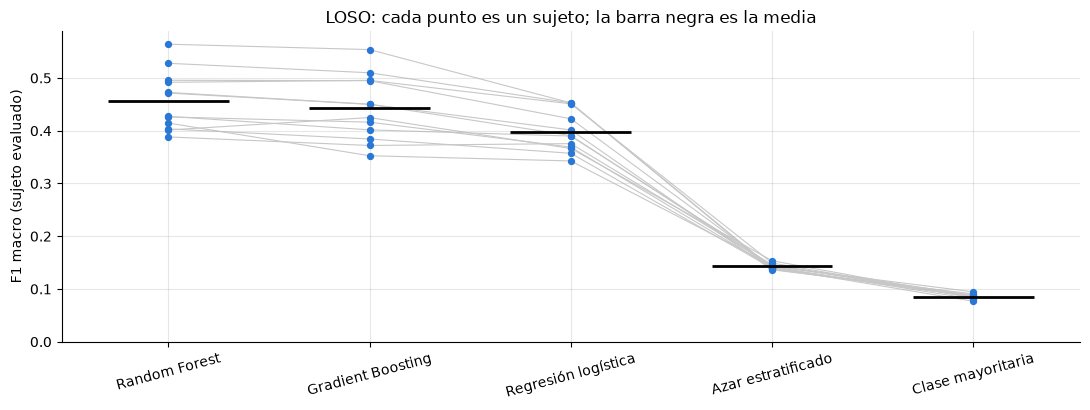

F1 por clase (media de sujetos):


,F1 N,F1 LF,F1 K,F1 PT,F1 LT,F1 W,F1 PF
modelo,,,,,,,
Random Forest,0.763,0.418,0.485,0.375,0.377,0.374,0.407
Gradient Boosting,0.731,0.404,0.462,0.366,0.384,0.357,0.393
Regresión logística,0.656,0.352,0.434,0.284,0.373,0.322,0.364
Azar estratificado,0.428,0.092,0.083,0.146,0.091,0.087,0.074
Clase mayoritaria,0.599,0.000,0.000,0.000,0.000,0.000,0.000


In [5]:
BEST_ORDER = list(summary.index)
wide = results.pivot(index="sujeto", columns="modelo", values="F1 macro")[BEST_ORDER]

fig, ax = plt.subplots(figsize=(11, 4.2))
for _, row in wide.iterrows():
    ax.plot(range(len(row)), row.to_numpy(), color="#c7c7c7", lw=0.8, zorder=1)
for j, name in enumerate(wide.columns):
    ax.scatter([j] * len(wide), wide[name], s=18, color="#2a78d6", zorder=2)
    ax.hlines(wide[name].mean(), j - 0.3, j + 0.3, color="black", lw=2, zorder=3)
ax.set(xticks=range(len(wide.columns)), ylabel="F1 macro (sujeto evaluado)", ylim=(0, None),
       title="LOSO: cada punto es un sujeto; la barra negra es la media")
ax.set_xticklabels(wide.columns, rotation=15)
plt.tight_layout()
plt.show()

print("F1 por clase (media de sujetos):")
display(results.groupby("modelo")[[f"F1 {l}" for l in LABELS]].mean().loc[BEST_ORDER].round(3))

### Comparaciones pareadas

Cada sujeto se compara **consigo mismo** con dos modelos, lo que elimina la variación entre personas. La **prueba de rangos con signo de Wilcoxon** evalúa si las diferencias tienden a ir en la misma dirección. No supone normalidad y funciona con pocas observaciones pareadas (12 sujetos). Junto al p-valor se reporta en cuántos sujetos gana cada modelo, que es más fácil de interpretar.

In [6]:
def paired(table_wide, a, b):
    both = table_wide[[a, b]].dropna()
    diff = both[a] - both[b]
    p = wilcoxon(both[a], both[b]).pvalue if len(both) >= 6 and (diff != 0).any() else np.nan
    return {"A": a, "B": b, "diferencia media (A − B)": diff.mean(), "sujetos donde A gana": f"{int((diff > 0).sum())} de {len(both)}",
            "p (Wilcoxon)": p}


best_tabular = BEST_ORDER[0]
pairs = [paired(wide, m, "Azar estratificado") for m in ("Regresión logística", "Random Forest", "Gradient Boosting")]
pairs += [paired(wide, "Random Forest", "Regresión logística"), paired(wide, "Gradient Boosting", "Regresión logística"),
          paired(wide, "Random Forest", "Gradient Boosting")]
display(pd.DataFrame(pairs).set_index(["A", "B"]).round(4))
print(f"Mejor baseline por F1 macro medio: {best_tabular}")

,,diferencia media (A − B),sujetos donde A gana,p (Wilcoxon)
A,B,,,
Regresión logística,Azar estratificado,0.2547,12 de 12,0.0005
Random Forest,Azar estratificado,0.3141,12 de 12,0.0005
Gradient Boosting,Azar estratificado,0.2992,12 de 12,0.0005
Random Forest,Regresión logística,0.0594,12 de 12,0.0005
Gradient Boosting,Regresión logística,0.0445,11 de 12,0.0010
Random Forest,Gradient Boosting,0.0149,10 de 12,0.0342


Mejor baseline por F1 macro medio: Random Forest


### Matriz de confusión del mejor baseline

Cada fila es la actividad real y cada columna la predicha. Los valores son el porcentaje de las ventanas de esa actividad, sumando los 12 sujetos. La diagonal es el *recall* de cada clase.

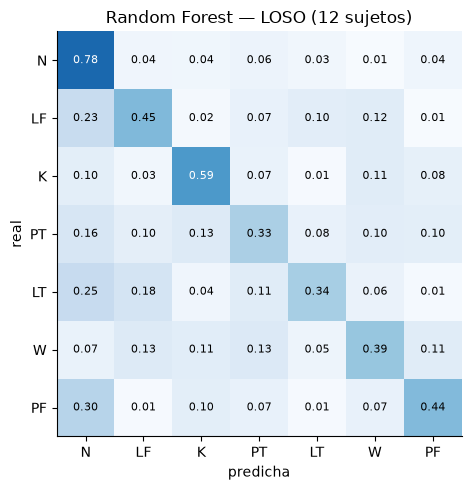

In [7]:
p = predictions[best_tabular]
cm = confusion_matrix(p["y"], p["pred"], labels=range(len(LABELS)), normalize="true")
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(LABELS)), yticks=range(len(LABELS)), xticklabels=LABELS, yticklabels=LABELS,
       xlabel="predicha", ylabel="real", title=f"{best_tabular} — LOSO (12 sujetos)")
ax.grid(False)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else "black")
plt.tight_layout()
plt.show()

# 5. ¿El modelo está sub o sobreajustando?

**Conceptos:**

- **Subajuste** (*underfitting*): el modelo es demasiado simple para captar los patrones. Le va mal **incluso con los datos con los que entrenó**.
- **Sobreajuste** (*overfitting*): el modelo memoriza detalles de los datos de entrenamiento (aquí, de los 11 sujetos con los que entrena) que no se repiten en datos nuevos. Le va muy bien en entrenamiento y mucho peor con el sujeto nuevo.

Se usan tres diagnósticos:

1. **Brecha entrenamiento–evaluación:** el F1 en los datos de entrenamiento contra el F1 en el sujeto que quedó fuera.
2. **Curva de aprendizaje:** cómo cambia el F1 al entrenar con más o menos **sujetos**. Si sigue subiendo, más personas ayudarían.
3. **Curva de validación:** cómo cambia el F1 al hacer el modelo más o menos flexible (regularización).

,F1 entrenamiento,F1 sujeto nuevo (LOSO),brecha
modelo,,,
Random Forest,0.930,0.457,0.473
Gradient Boosting,0.842,0.442,0.400
Regresión logística,0.486,0.398,0.088


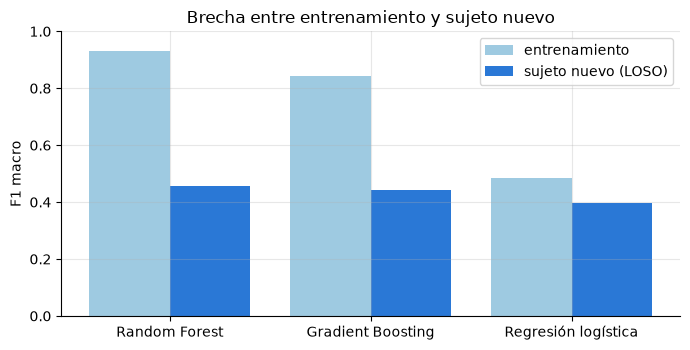

In [8]:
gap = (results[~results["modelo"].str.startswith(("Azar", "Clase"))]
       .groupby("modelo")[["F1 entrenamiento", "F1 macro"]].mean().loc[[m for m in BEST_ORDER if not m.startswith(("Azar", "Clase"))]])
gap["brecha"] = gap["F1 entrenamiento"] - gap["F1 macro"]
display(gap.rename(columns={"F1 macro": "F1 sujeto nuevo (LOSO)"}).round(3))

fig, ax = plt.subplots(figsize=(7, 3.6))
xpos = np.arange(len(gap))
ax.bar(xpos - 0.2, gap["F1 entrenamiento"], 0.4, label="entrenamiento", color="#9ecae1")
ax.bar(xpos + 0.2, gap["F1 macro"], 0.4, label="sujeto nuevo (LOSO)", color="#2a78d6")
ax.set(xticks=xpos, xticklabels=gap.index, ylabel="F1 macro", ylim=(0, 1), title="Brecha entre entrenamiento y sujeto nuevo")
ax.legend()
plt.tight_layout()
plt.show()

### 5.1 Curva de aprendizaje: ¿ayudarían más sujetos?

Para cada sujeto evaluado se entrena con 1, 2, 4, 6, 8 y 11 sujetos elegidos al azar entre los demás.

- **Si el F1 en el sujeto nuevo sigue subiendo al agregar personas,** el problema está limitado por **cuántas personas** hay, no por el modelo.
- **Si la curva se aplana,** agregar sujetos ya no ayudaría y habría que mejorar las características o el modelo.

Se calcula para la regresión logística y el Random Forest, el representante de los modelos de árboles: es el más rápido de ajustar y sus resultados LOSO son cercanos a los del Gradient Boosting.

Curva de aprendizaje: 7.6 min


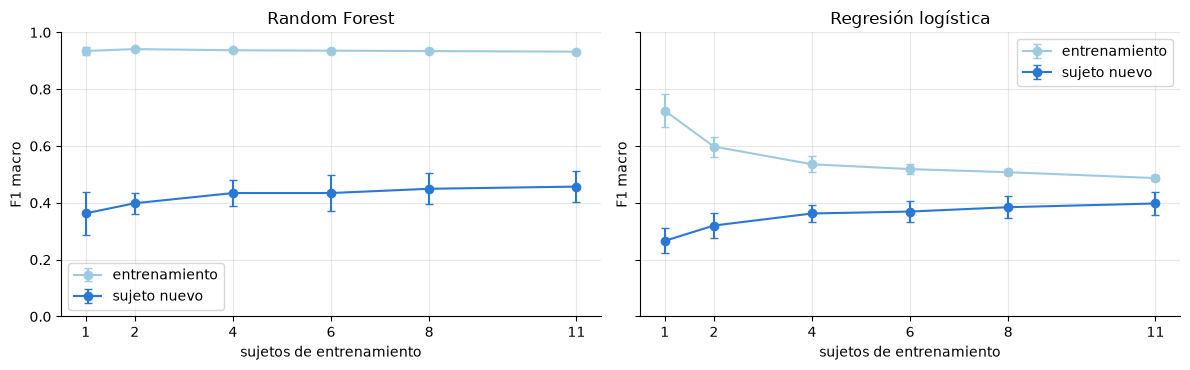

mean                               std                    
modelo    Random Forest Regresión logística Random Forest Regresión logística
n sujetos                                                                    
1                 0.363               0.266         0.075               0.044
2                 0.399               0.320         0.037               0.044
4                 0.434               0.363         0.047               0.028
6                 0.434               0.369         0.062               0.036
8                 0.449               0.385         0.055               0.039
11                0.457               0.398         0.056               0.039

In [9]:
N_TRAIN = [1, 2, 4, 6, 8, 11] if not QUICK else [1, 4]
curve_models = {"Regresión logística": MODELS["Regresión logística"], "Random Forest": MODELS["Random Forest"]}
rng = np.random.default_rng(SEED)
curve_rows = []
t0 = time.time()
for s in FOLD_SUBJECTS:
    others = [o for o in DEV_SUBJECTS if o != s]
    test_idx = np.flatnonzero(groups == s)
    for n in N_TRAIN:
        chosen = rng.choice(others, size=min(n, len(others)), replace=False)
        train_idx = stratified_cap(np.flatnonzero(np.isin(groups, chosen)), TRAIN_CAP, rng)
        for name, make_model in curve_models.items():
            model = make_model().fit(X[train_idx], y[train_idx])
            sample = stratified_cap(train_idx, 10_000, rng)
            curve_rows.append({"modelo": name, "sujeto": s, "n sujetos": n,
                               "entrenamiento": f1_score(y[sample], model.predict(X[sample]), average="macro"),
                               "sujeto nuevo": f1_score(y[test_idx], model.predict(X[test_idx]), average="macro")})
print(f"Curva de aprendizaje: {(time.time() - t0) / 60:.1f} min")
learning = pd.DataFrame(curve_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, g) in zip(axes, learning.groupby("modelo")):
    agg = g.groupby("n sujetos")[["entrenamiento", "sujeto nuevo"]].agg(["mean", "std"])
    for col, color in (("entrenamiento", "#9ecae1"), ("sujeto nuevo", "#2a78d6")):
        ax.errorbar(agg.index, agg[(col, "mean")], yerr=agg[(col, "std")], marker="o", capsize=3, color=color, label=col)
    ax.set(title=name, xlabel="sujetos de entrenamiento", ylabel="F1 macro", ylim=(0, 1), xticks=N_TRAIN)
    ax.legend()
plt.tight_layout()
plt.show()
display(learning.groupby(["modelo", "n sujetos"])["sujeto nuevo"].agg(["mean", "std"]).unstack(0).round(3))

### 5.2 Curva de validación: ¿más o menos flexibilidad?

Se varía el parámetro que controla la **complejidad** de cada modelo:

- **Regresión logística — `C`:** inverso de la regularización. Con `C` pequeño el modelo se "frena" (coeficientes pequeños, más simple); con `C` grande se ajusta más a los datos.
- **Random Forest — `min_samples_leaf`:** el mínimo de ventanas en cada hoja de un árbol. Con 1, los árboles pueden aprender casos individuales y memorizar; con valores grandes, las reglas se vuelven más generales.

Para que sea más rápido se usan 6 pliegues de 2 sujetos (`GroupKFold`). Cada pliegue sigue evaluando con personas no vistas.

Curvas de validación: 4.3 min


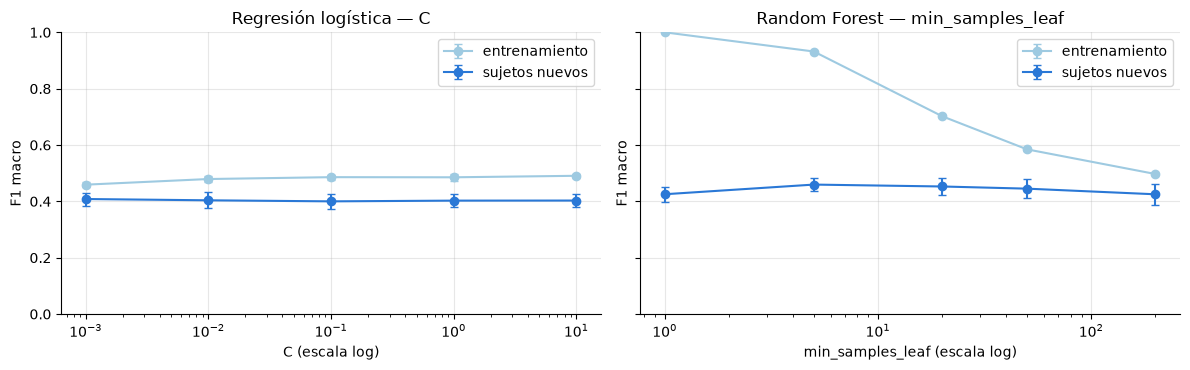

entrenamiento  sujetos nuevos
curva                            valor                                 
Random Forest — min_samples_leaf 1.000            1.000           0.425
                                 5.000            0.932           0.460
                                 20.000           0.702           0.453
                                 50.000           0.585           0.445
                                 200.000          0.497           0.425
Regresión logística — C          0.001            0.459           0.408
                                 0.010            0.479           0.404
                                 0.100            0.486           0.400
                                 1.000            0.485           0.403
                                 10.000           0.491           0.403

In [10]:
cv = GroupKFold(n_splits=6 if not QUICK else 2)
grids = {
    "Regresión logística — C": ("C", [1e-3, 1e-2, 1e-1, 1, 10],
        lambda v: make_pipeline(StandardScaler(), LogisticRegression(C=v, max_iter=2000, class_weight="balanced"))),
    "Random Forest — min_samples_leaf": ("min_samples_leaf", [1, 5, 20, 50, 200],
        lambda v: RandomForestClassifier(n_estimators=150, min_samples_leaf=v, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
}
rng = np.random.default_rng(SEED)
val_rows = []
t0 = time.time()
for title, (param, values, build) in grids.items():
    for v in values:
        for train_idx, test_idx in cv.split(X, y, groups):
            train_idx = stratified_cap(train_idx, TRAIN_CAP, rng)
            model = build(v).fit(X[train_idx], y[train_idx])
            sample = stratified_cap(train_idx, 10_000, rng)
            val_rows.append({"curva": title, "valor": v,
                             "entrenamiento": f1_score(y[sample], model.predict(X[sample]), average="macro"),
                             "sujetos nuevos": f1_score(y[test_idx], model.predict(X[test_idx]), average="macro")})
print(f"Curvas de validación: {(time.time() - t0) / 60:.1f} min")
validation = pd.DataFrame(val_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (title, g) in zip(axes, validation.groupby("curva", sort=False)):
    agg = g.groupby("valor")[["entrenamiento", "sujetos nuevos"]].agg(["mean", "std"])
    for col, color in (("entrenamiento", "#9ecae1"), ("sujetos nuevos", "#2a78d6")):
        ax.errorbar(agg.index, agg[(col, "mean")], yerr=agg[(col, "std")], marker="o", capsize=3, color=color, label=col)
    ax.set(title=title, xscale="log", xlabel=title.split(" — ")[1] + " (escala log)", ylabel="F1 macro", ylim=(0, 1))
    ax.legend()
plt.tight_layout()
plt.show()
display(validation.groupby(["curva", "valor"])[["entrenamiento", "sujetos nuevos"]].mean().round(3))

### 5.3 Medidas contra el sobreajuste

Los diagnósticos anteriores muestran dos problemas distintos, y cada uno se ataca de otra forma:

- **Random Forest — sobreajuste a los sujetos.** Memoriza rasgos propios de las 11 personas con las que entrena (su amplitud, su colocación de electrodos, su forma de moverse) que no sirven con una persona nueva.
- **Regresión logística — subajuste.** Es demasiado simple (lineal) para captar la relación entre las características y la actividad.

Se prueban cuatro medidas con el mismo LOSO y se comparan sujeto por sujeto con el modelo original:

| Medida | Qué hace | Para qué modelo |
| :--- | :--- | :--- |
| **Estandarización por sujeto** | A las características de cada persona se les resta **su propia** media y se dividen entre **su propia** desviación, calculadas con todas sus ventanas y **sin usar etiquetas** | Ambos: elimina el "sello" de cada persona y deja sólo las variaciones *dentro* de ella, que son las que indican la actividad |
| **Árboles más regularizados** | Hojas con al menos 20 ventanas, profundidad máxima de 15 niveles y cada árbol entrenado con la mitad de los datos | Random Forest: reglas más generales y árboles más distintos entre sí |
| ***Splines* sobre cuantiles** | `QuantileTransformer` lleva cada característica a una distribución normal (corrige la asimetría); `SplineTransformer` la convierte en varias curvas suaves por tramos | Regresión logística: puede aprender relaciones no lineales (en forma de U, umbrales) sin dejar de ser un modelo lineal sobre esas curvas |
| **Suavizado temporal** (sección 5.4) | Promedia las probabilidades de la ventana actual con las de las ventanas **anteriores** del mismo ensayo | Cualquier modelo: reduce errores aislados sin mirar el futuro |

**Sobre la estandarización por sujeto:** para el sujeto evaluado se usan sus propias ventanas **sin etiquetas**. En un uso real equivale a una **calibración**: registrar unos minutos de actividad de la persona nueva antes de usar el sistema, sin que nadie anote qué hacía. No hay fuga de información sobre las actividades.

RF + z por sujeto                              F1 macro 0.485 ± 0.042


RF regularizado                                F1 macro 0.449 ± 0.059


RF regularizado + z por sujeto                 F1 macro 0.470 ± 0.053


Regresión logística + z por sujeto             F1 macro 0.412 ± 0.045


Regresión logística + splines                  F1 macro 0.418 ± 0.051


Regresión logística + splines + z por sujeto   F1 macro 0.381 ± 0.050
Variantes: 8.8 min


,F1 entrenamiento,F1 sujeto nuevo,desv.,brecha,comparado con,Δ F1,sujetos que mejoran,p (Wilcoxon)
modelo,,,,,,,,
Random Forest,0.930,0.457,0.056,0.473,NaN,NaN,NaN,NaN
Regresión logística,0.486,0.398,0.039,0.088,NaN,NaN,NaN,NaN
RF + z por sujeto,0.932,0.485,0.042,0.447,Random Forest,0.028,11 de 12,0.002
RF regularizado,0.626,0.449,0.059,0.177,Random Forest,-0.008,3 de 12,0.092
RF regularizado + z por sujeto,0.636,0.470,0.053,0.165,Random Forest,0.013,8 de 12,0.092
Regresión logística + z por sujeto,0.500,0.412,0.045,0.087,Regresión logística,0.015,8 de 12,0.110
Regresión logística + splines,0.573,0.418,0.051,0.156,Regresión logística,0.020,10 de 12,0.007
Regresión logística + splines + z por sujeto,0.586,0.381,0.050,0.206,Regresión logística,-0.017,3 de 12,0.092


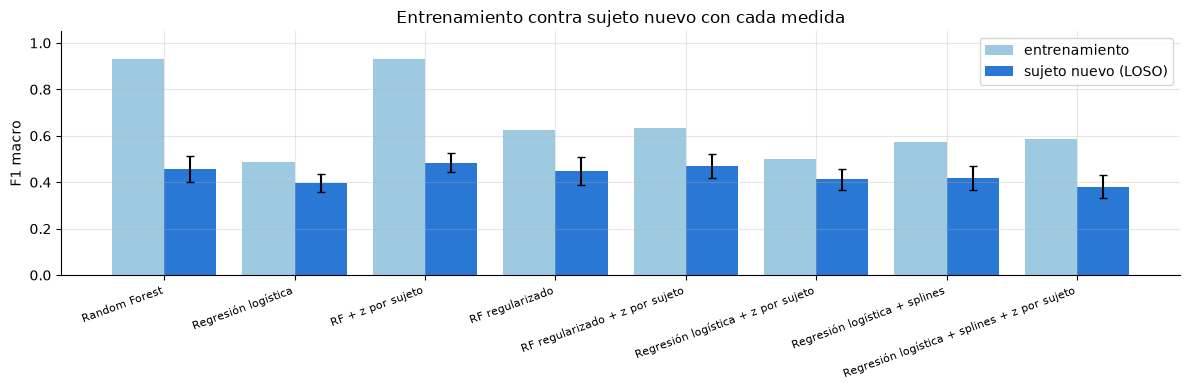

Mejor variante: RF + z por sujeto (F1 0.485)


In [11]:
def standardize_by_subject(data, subject_ids):
    """z-score de cada característica dentro de cada sujeto (sin usar etiquetas)."""
    out = np.empty_like(data)
    for s in np.unique(subject_ids):
        m = subject_ids == s
        mu, sd = data[m].mean(axis=0), data[m].std(axis=0)
        out[m] = (data[m] - mu) / np.where(sd > 0, sd, 1.0)
    return out


X_SUBJ = standardize_by_subject(X, groups)

rf_regularized = lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_depth=15, max_samples=0.5,
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
lr_splines = lambda: make_pipeline(QuantileTransformer(output_distribution="normal", subsample=20_000, random_state=SEED),
                                   SplineTransformer(n_knots=4, degree=2), StandardScaler(),
                                   LogisticRegression(C=0.1, max_iter=1000, class_weight="balanced"))

VARIANTS = {   # nombre: (modelo, datos, modelo original con el que se compara)
    "RF + z por sujeto": (MODELS["Random Forest"], X_SUBJ, "Random Forest"),
    "RF regularizado": (rf_regularized, X, "Random Forest"),
    "RF regularizado + z por sujeto": (rf_regularized, X_SUBJ, "Random Forest"),
    "Regresión logística + z por sujeto": (MODELS["Regresión logística"], X_SUBJ, "Regresión logística"),
    "Regresión logística + splines": (lr_splines, X, "Regresión logística"),
    "Regresión logística + splines + z por sujeto": (lr_splines, X_SUBJ, "Regresión logística"),
}
variant_results = [results[results["modelo"].isin(["Random Forest", "Regresión logística"])]]
t0 = time.time()
for name, (make_model, data, _) in VARIANTS.items():
    r, _ = loso_eval(make_model, name=name, data=data)
    variant_results.append(r)
    print(f"{name:<46} F1 macro {r['F1 macro'].mean():.3f} ± {r['F1 macro'].std():.3f}")
print(f"Variantes: {(time.time() - t0) / 60:.1f} min")
variant_results = pd.concat(variant_results, ignore_index=True)
vwide = variant_results.pivot(index="sujeto", columns="modelo", values="F1 macro")

rows = []
for name in ["Random Forest", "Regresión logística", *VARIANTS]:
    g = variant_results[variant_results["modelo"] == name]
    row = {"modelo": name, "F1 entrenamiento": g["F1 entrenamiento"].mean(), "F1 sujeto nuevo": g["F1 macro"].mean(),
           "desv.": g["F1 macro"].std(), "brecha": g["F1 entrenamiento"].mean() - g["F1 macro"].mean()}
    if name in VARIANTS:
        base = VARIANTS[name][2]
        pr = paired(vwide, name, base)
        row.update({"comparado con": base, "Δ F1": pr["diferencia media (A − B)"], "sujetos que mejoran": pr["sujetos donde A gana"],
                    "p (Wilcoxon)": pr["p (Wilcoxon)"]})
    rows.append(row)
remedies = pd.DataFrame(rows).set_index("modelo")
display(remedies.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
xpos = np.arange(len(remedies))
ax.bar(xpos - 0.2, remedies["F1 entrenamiento"], 0.4, label="entrenamiento", color="#9ecae1")
ax.bar(xpos + 0.2, remedies["F1 sujeto nuevo"], 0.4, yerr=remedies["desv."], capsize=3, label="sujeto nuevo (LOSO)", color="#2a78d6")
ax.set(xticks=xpos, ylabel="F1 macro", ylim=(0, 1.05), title="Entrenamiento contra sujeto nuevo con cada medida")
ax.set_xticklabels(remedies.index, rotation=20, ha="right", fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()

IMPROVED_NAME = remedies["F1 sujeto nuevo"].idxmax()
print(f"Mejor variante: {IMPROVED_NAME} (F1 {remedies.loc[IMPROVED_NAME, 'F1 sujeto nuevo']:.3f})")

**Lectura del resultado:**

- **Estandarizar por sujeto es la medida que funciona.**
  - En el Random Forest el F1 sube de 0.457 a **0.485** y mejora en **11 de 12 sujetos** (p = 0.002).
  - Además, la dispersión entre personas baja de ±0.056 a **±0.042**: el modelo depende menos de quién sea el usuario.
- **Reducir la brecha no es lo mismo que generalizar mejor.**
  - Los árboles más regularizados bajan la brecha entrenamiento–evaluación de 0.47 a 0.18, pero el F1 con sujetos nuevos **no mejora** (0.449, mejora sólo en 3 de 12).
  - En cambio, la estandarización por sujeto deja la brecha casi igual (0.45) y aun así mejora.

  El F1 de entrenamiento alto no era el problema: el modelo puede "memorizar" a las personas de entrenamiento sin perjudicar a las nuevas. Lo que perjudicaba eran las **diferencias entre personas**, y eso es lo que corrige la estandarización.
- **Regresión logística:** los ***splines*** corrigen parte del subajuste.
  - El F1 de entrenamiento sube de 0.49 a 0.57 y el de sujetos nuevos de 0.398 a **0.418** (mejora en 10 de 12, p = 0.007).
  - La estandarización por sujeto le ayuda poco (+0.015, no significativo), y combinar ambas medidas empeora el resultado (0.381).
  - Aun mejorada, queda lejos del Random Forest: la relación entre las características y la actividad es fuertemente no lineal.
- **Combinar regularización y estandarización** en el Random Forest (0.470) rinde menos que la estandarización sola.

**Decisión:** el baseline pasa a ser **Random Forest con estandarización por sujeto** (F1 0.485 ± 0.042).

### 5.4 Suavizado temporal de las predicciones

Las ventanas consecutivas de un ensayo están separadas sólo 0.5 s, y la actividad casi nunca cambia tan rápido. Promediar las **probabilidades** de la ventana actual con las de las `w − 1` ventanas **anteriores** reduce los errores aislados (una ventana de `LT` que "salta" a `PT` y regresa).

El suavizado es **causal**: sólo usa el pasado, así que también funcionaría en tiempo real. A cambio, puede **retrasar** la detección de un cambio de actividad. Se prueba con la mejor variante de la sección 5.3, con `w` = 1 (sin suavizar), 2, 3 y 4 ventanas (hasta 1.5 s de historia).

In [12]:
best_make, best_data, _ = VARIANTS.get(IMPROVED_NAME, (MODELS[IMPROVED_NAME] if IMPROVED_NAME in MODELS else MODELS["Random Forest"], X, None))
prob_rows = []
for s in FOLD_SUBJECTS:
    train_idx = np.flatnonzero(groups != s)
    test_idx = np.flatnonzero(groups == s)
    model = best_make().fit(best_data[train_idx], y[train_idx])
    frame = dev.loc[test_idx, ["subject", "trial_idx", "end_step"]].copy()
    frame["y"] = y[test_idx]
    proba = model.predict_proba(best_data[test_idx])
    prob_rows.append(pd.concat([frame.reset_index(drop=True), pd.DataFrame(proba, columns=LABELS)], axis=1))
probs = pd.concat(prob_rows, ignore_index=True).sort_values(["subject", "trial_idx", "end_step"])

smooth_rows, smooth_wide = [], {}
for w in [1, 2, 3, 4]:
    smoothed = probs.groupby(["subject", "trial_idx"])[LABELS].transform(lambda c: c.rolling(w, min_periods=1).mean())
    pred = smoothed.to_numpy().argmax(axis=1)
    per_subject = pd.Series({s: f1_score(probs["y"][probs["subject"] == s], pred[(probs["subject"] == s).to_numpy()], average="macro")
                             for s in FOLD_SUBJECTS})
    smooth_wide[f"w = {w}"] = per_subject
    smooth_rows.append({"ventanas promediadas (w)": w, "historia (s)": (w - 1) * 0.5, "F1 macro": per_subject.mean(), "desv.": per_subject.std()})
smooth_wide = pd.DataFrame(smooth_wide)
smoothing = pd.DataFrame(smooth_rows).set_index("ventanas promediadas (w)")
best_w = int(smoothing["F1 macro"].idxmax())
pr = paired(smooth_wide, f"w = {best_w}", "w = 1") if best_w != 1 else None
display(smoothing.round(3))
if pr:
    print(f"Mejor suavizado: w = {best_w} | Δ F1 {pr['diferencia media (A − B)']:+.3f} | mejora en {pr['sujetos donde A gana']} sujetos | p = {pr['p (Wilcoxon)']:.4f}")
IMPROVED_SMOOTH = smooth_wide[f"w = {best_w}"]

,historia (s),F1 macro,desv.
ventanas promediadas (w),,,
1,0.0,0.485,0.042
2,0.5,0.478,0.045
3,1.0,0.458,0.046
4,1.5,0.431,0.050


**Lectura del resultado:** el suavizado **empeora** el resultado, y más cuanto más se promedia:

| Ventanas promediadas | F1 |
| :---: | :---: |
| sin suavizar | 0.485 |
| 2 | 0.478 |
| 3 | 0.458 |
| 4 | 0.431 |

La causa es la regla de etiquetado: cada ventana lleva la etiqueta de su **instante final**. Al promediar con ventanas anteriores, justo después de un cambio de actividad la predicción arrastra la actividad previa durante más tiempo, y esos errores en las transiciones pesan más que los errores aislados que el suavizado corrige.

**Decisión:** no se suaviza.

# 6. Importancia de las características

**Técnica: importancia por permutación.** Para medir cuánto depende el modelo de una característica, se **desordena al azar** su columna en los datos del sujeto evaluado (rompiendo su relación con la actividad) y se mide **cuánto baja el F1**.

- Si baja mucho, el modelo depende de ella.
- Si no cambia, el modelo no la usa.
- Si sube, la característica sólo agrega ruido.

Ventajas frente a la importancia interna de los árboles (`feature_importances_`):

- funciona con **cualquier** modelo;
- se mide sobre **sujetos no vistos**, que es lo que importa;
- no favorece a las variables con muchos valores distintos.

Como hay 202 características muy correlacionadas entre sí (el avance 2 encontró 106 pares con |ρ| > 0.95), desordenar una sola a la vez **subestima** su importancia: el modelo usa su "gemela". Por eso también se permutan **grupos completos**:

- **por familia:** nivel, dispersión, dinámica, espectral, coactivación y globales;
- **por canal:** todas las características de cada canal.

Se calcula con el **mejor baseline**, reentrenándolo en cada pliegue LOSO.

Importancia por permutación (Random Forest): 5.2 min


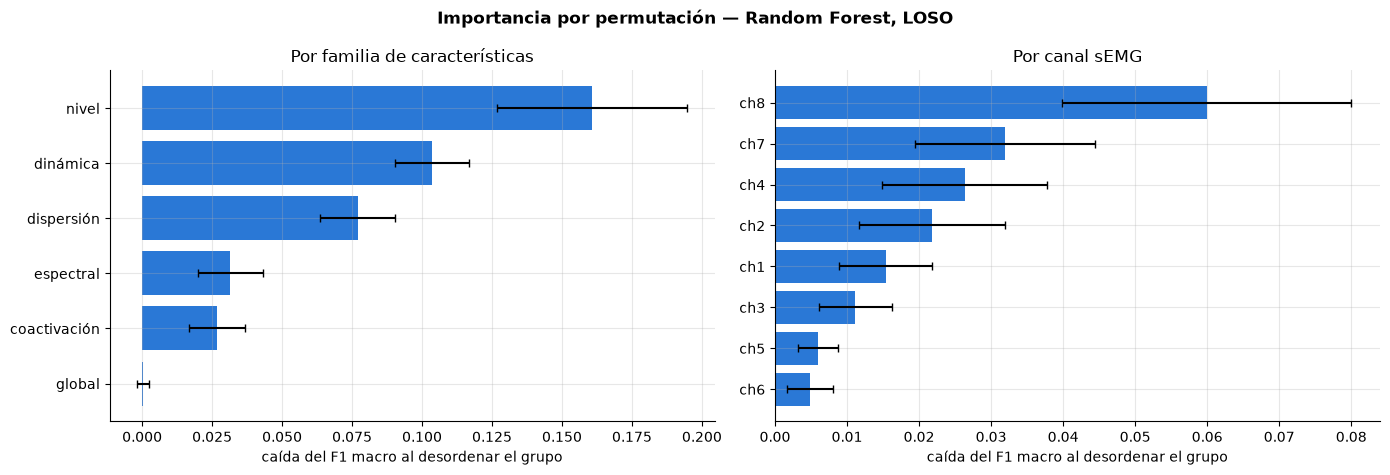

In [13]:
import re

PER_CHANNEL = re.compile(r"^ch\d+_")                  # características de un canal: ch1_mean, ch8_slope, ...


def feature_family(name):
    stat = name.split("_", 1)[1] if PER_CHANNEL.match(name) else name
    if name.startswith("corr_") or stat in ("between_channel_std", "dominant_channel_share", "channel_activation_entropy"):
        return "coactivación"
    if name.startswith("global_"):
        return "global"
    if stat in ("slope", "mean_abs_slope"):
        return "dinámica"
    if stat in ("dominant_hz", "spectral_centroid_hz", "spectral_entropy") or stat.startswith("relpower"):
        return "espectral"
    if stat in ("std", "iqr", "mad", "range", "tail_std"):
        return "dispersión"
    return "nivel"


FAMILY = np.array([feature_family(f) for f in FEATURES])
CHANNEL = np.array([f.split("_", 1)[0] if PER_CHANNEL.match(f) else "multicanal" for f in FEATURES])
GROUPS = {**{f"familia: {g}": np.flatnonzero(FAMILY == g) for g in pd.unique(FAMILY)},
          **{f"canal: {c}": np.flatnonzero(CHANNEL == c) for c in sorted(set(CHANNEL) - {"multicanal"})}}


def permutation_drop(model, Xte, yte, columns, rng, repeats=3):
    """Caída media del F1 macro al desordenar juntas las columnas indicadas."""
    base = f1_score(yte, model.predict(Xte), average="macro")
    drops = []
    for _ in range(repeats):
        Xp = Xte.copy()
        perm = rng.permutation(len(Xp))
        Xp[:, columns] = Xp[perm][:, columns]           # mismo desorden para todo el grupo
        drops.append(base - f1_score(yte, model.predict(Xp), average="macro"))
    return float(np.mean(drops))


rng = np.random.default_rng(SEED)
group_rows, single_rows = [], []
t0 = time.time()
for s in FOLD_SUBJECTS:
    train_idx = stratified_cap(np.flatnonzero(groups != s), TRAIN_CAP, rng)
    test_idx = np.flatnonzero(groups == s)
    model = MODELS[best_tabular]().fit(X[train_idx], y[train_idx])
    Xte, yte = X[test_idx], y[test_idx]
    for gname, cols in GROUPS.items():
        group_rows.append({"sujeto": s, "grupo": gname, "caída F1": permutation_drop(model, Xte, yte, cols, rng)})
    sub = stratified_cap(np.arange(len(yte)), 2_500, rng)          # submuestra para las 202 permutaciones individuales
    for j, feat in enumerate(FEATURES):
        single_rows.append({"sujeto": s, "característica": feat, "caída F1": permutation_drop(model, Xte[sub], yte[sub], [j], rng, repeats=1)})
print(f"Importancia por permutación ({best_tabular}): {(time.time() - t0) / 60:.1f} min")
group_imp = pd.DataFrame(group_rows).groupby("grupo")["caída F1"].agg(["mean", "std"]).sort_values("mean", ascending=False)
single_imp = pd.DataFrame(single_rows).groupby("característica")["caída F1"].agg(["mean", "std"]).sort_values("mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
fam = group_imp[group_imp.index.str.startswith("familia")]
ch = group_imp[group_imp.index.str.startswith("canal")]
for ax, g, title in ((axes[0], fam, "Por familia de características"), (axes[1], ch, "Por canal sEMG")):
    ax.barh(g.index.str.split(": ").str[1], g["mean"], xerr=g["std"], color="#2a78d6", capsize=3)
    ax.invert_yaxis()
    ax.set(xlabel="caída del F1 macro al desordenar el grupo", title=title)
fig.suptitle(f"Importancia por permutación — {best_tabular}, LOSO", fontweight="bold")
plt.tight_layout()
plt.show()

**Características individuales.** Las 20 más importantes, y cuántas tienen importancia **nula o negativa**: desordenarlas no empeora, o hasta mejora, la predicción en sujetos nuevos.

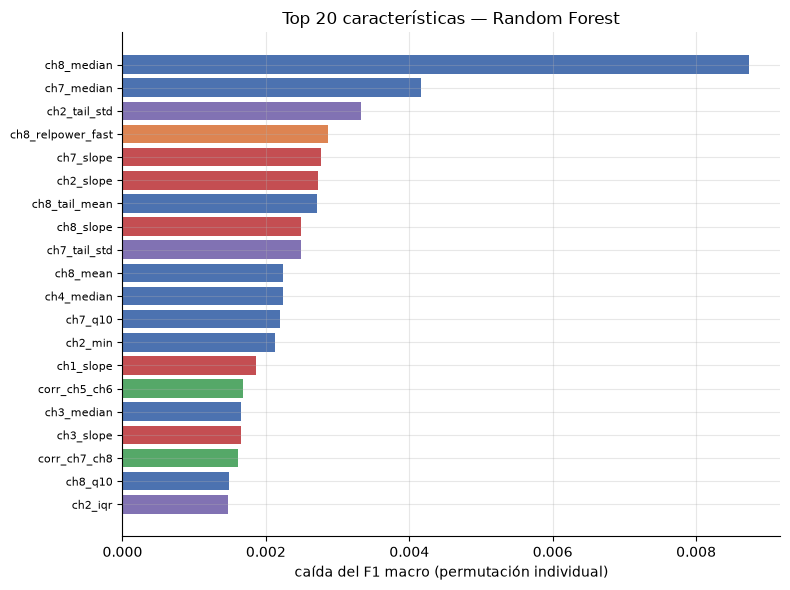

Características con importancia individual ≤ 0: 85 de 202


,espectral,nivel,coactivación,dispersión,dinámica,global
por familia,23,20,18,14,8,2


In [14]:
top = single_imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["mean"], color=[{"nivel": "#4c72b0", "dispersión": "#8172b3", "dinámica": "#c44e52", "espectral": "#dd8452",
                                        "coactivación": "#55a868", "global": "#937860"}[feature_family(f)] for f in top.index])
ax.set(xlabel="caída del F1 macro (permutación individual)", title=f"Top 20 características — {best_tabular}")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

irrelevant = single_imp[single_imp["mean"] <= 0].index.tolist()
print(f"Características con importancia individual ≤ 0: {len(irrelevant)} de {len(FEATURES)}")
display(pd.Series([feature_family(f) for f in irrelevant]).value_counts().rename("por familia").to_frame().T)

### 6.1 ¿Quitar características mejora o empeora el modelo?

La rúbrica advierte que incluir características irrelevantes puede empeorar el modelo y aumentar su complejidad. Para comprobarlo, se reentrena el mejor baseline conservando sólo las **k mejores** según la prueba **ANOVA F** (`SelectKBest`). Esta prueba compara cuánto cambia el valor medio de una característica entre clases contra cuánto varía dentro de cada clase.

La selección se hace **dentro de cada pliegue**, sólo con los sujetos de entrenamiento. Seleccionar con todos los datos, o con la importancia por permutación de arriba, que se midió en los sujetos de evaluación, sería fuga de información.

Ablación: 6.8 min


,F1 macro,desv.,F1 entrenamiento,seg por pliegue
k características,,,,
10,0.385,0.053,0.846,2.891
25,0.416,0.059,0.892,4.457
50,0.417,0.059,0.914,6.072
100,0.448,0.057,0.921,8.558
202,0.457,0.056,0.930,11.732


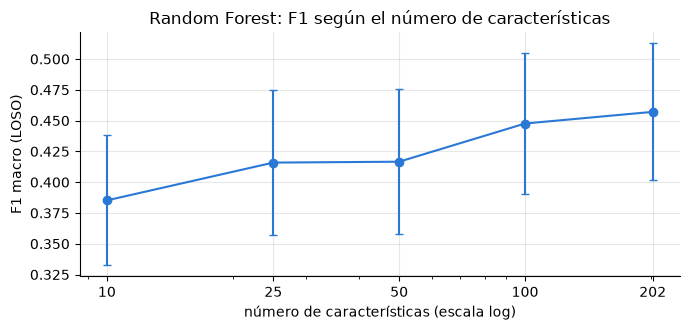

In [15]:
K_VALUES = [10, 25, 50, 100, len(FEATURES)] if not QUICK else [10, len(FEATURES)]
abl_rows = []
t0 = time.time()
for k in K_VALUES:
    make = lambda k=k: make_pipeline(SelectKBest(f_classif, k=k), MODELS[best_tabular]())
    r, _ = loso_eval(make, name=f"k = {k}")
    abl_rows.append({"k características": k, "F1 macro": r["F1 macro"].mean(), "desv.": r["F1 macro"].std(),
                     "F1 entrenamiento": r["F1 entrenamiento"].mean(), "seg por pliegue": r["segundos"].mean()})
print(f"Ablación: {(time.time() - t0) / 60:.1f} min")
ablation = pd.DataFrame(abl_rows).set_index("k características")
display(ablation.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.errorbar(ablation.index, ablation["F1 macro"], yerr=ablation["desv."], marker="o", capsize=3, color="#2a78d6")
ax.set(xscale="log", xlabel="número de características (escala log)", ylabel="F1 macro (LOSO)",
       title=f"{best_tabular}: F1 según el número de características")
ax.set_xticks(K_VALUES)
ax.set_xticklabels(K_VALUES)
plt.tight_layout()
plt.show()

# 7. ¿Cuál debería ser el desempeño mínimo?

Un desempeño "mínimo" sólo tiene sentido **frente a referencias medidas con el mismo protocolo**. Se definen tres niveles:

1. **Piso (azar):** el F1 del clasificador estratificado. Un modelo por debajo de este nivel no extrae información de la señal.
2. **Mínimo aceptable (baseline):** el F1 del mejor baseline. Cualquier modelo más complejo (CPC–xLSTM) debe **superarlo de forma consistente**, en la mayoría de los sujetos y con una diferencia mayor que la variación entre personas, para justificar su costo.
3. **Referencia del equipo (CPC):** los resultados de las otras ramas, leídos del LOSO de CPC (`06_CPC_LOSO`) con **los mismos 12 sujetos y las mismas ventanas**, que permiten una comparación directa sujeto por sujeto.

,F1 macro,desv.
nivel,,
Baseline mejorado: RF + z por sujeto,0.485,0.042
Baseline mejorado + suavizado (w = 1),0.485,0.042
CPC sLSTM preentrenado + ajuste fino,0.462,0.054
Baseline: Random Forest,0.457,0.056
CPC mLSTM preentrenado + ajuste fino,0.430,0.065
CPC mLSTM congelado + regresión logística,0.411,0.058
Baseline lineal: regresión logística,0.398,0.039
Piso: azar estratificado,0.143,0.005


diferencia media (A − B)  \
A                             B                                               
CPC sLSTM                     Random Forest                          0.0046   
                              Regresión logística                    0.0639   
CPC mLSTM                     Random Forest                         -0.0275   
Baseline mejorado             CPC sLSTM                              0.0233   
Baseline mejorado + suavizado CPC sLSTM                              0.0233   

                                                  sujetos donde A gana  \
A                             B                                          
CPC sLSTM                     Random Forest                    7 de 12   
                              Regresión logística             12 de 12   
CPC mLSTM                     Random Forest                    1 de 12   
Baseline mejorado             CPC sLSTM                        9 de 12   
Baseline mejorado + suavizado CPC sLSTM                        9 de 12   

                                                   p (Wilcoxon)  
A                             B                                  
CPC sLSTM                     Random Forest              0.4697  
                              Regresión logística        0.0005  
CPC mLSTM                     Random Forest              0.0015  
Baseline mejorado             CPC sLSTM                  0.0342  
Baseline mejorado + suavizado CPC sLSTM                  0.0342

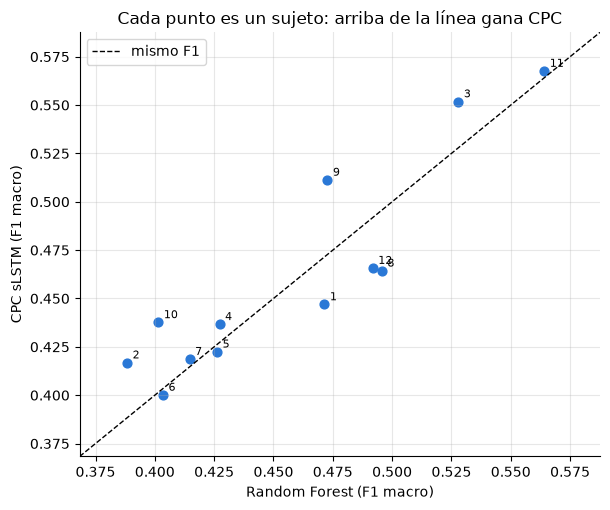

In [16]:
levels = [{"nivel": "Piso: azar estratificado", "F1 macro": wide["Azar estratificado"].mean(), "desv.": wide["Azar estratificado"].std()},
          {"nivel": f"Baseline: {best_tabular}", "F1 macro": wide[best_tabular].mean(), "desv.": wide[best_tabular].std()},
          {"nivel": "Baseline lineal: regresión logística", "F1 macro": wide["Regresión logística"].mean(), "desv.": wide["Regresión logística"].std()},
          {"nivel": f"Baseline mejorado: {IMPROVED_NAME}", "F1 macro": vwide[IMPROVED_NAME].mean(), "desv.": vwide[IMPROVED_NAME].std()},
          {"nivel": f"Baseline mejorado + suavizado (w = {best_w})", "F1 macro": IMPROVED_SMOOTH.mean(), "desv.": IMPROVED_SMOOTH.std()}]

def load_cpc_loso():
    """Resultados por sujeto del LOSO de CPC: del CSV resumen o, si no está en esta rama, de los .json por pliegue."""
    if CPC_LOSO_CSV.exists():
        return pd.read_csv(CPC_LOSO_CSV)
    run_dir = REPO_DIR / "checkpoints" / f"cpc06_loso_fs{TARGET_FS}"
    files = sorted(run_dir.glob("s*_*.json"))
    if not files:
        return None
    rows = [json.loads(f.read_text()) for f in files]
    return pd.DataFrame([{"sujeto": r["held_out"], "vista": r["view"], "F1": r["metrics"]["f1_macro"]} for r in rows])


cpc_wide = None
cpc = load_cpc_loso()
if cpc is not None:
    cpc_wide = cpc.pivot(index="sujeto", columns="vista", values="F1")
    for view, label in (("sLSTM_B_preentrenado", "CPC sLSTM preentrenado + ajuste fino"), ("mLSTM_A_preentrenado", "CPC mLSTM preentrenado + ajuste fino"),
                        ("mLSTM_A_sonda", "CPC mLSTM congelado + regresión logística")):
        if view in cpc_wide:
            levels.append({"nivel": label, "F1 macro": cpc_wide[view].mean(), "desv.": cpc_wide[view].std()})
else:
    print(f"[aviso] No se encontraron resultados del LOSO de CPC. Traer el CSV con:\n"
          f"  git restore --source=origin/trail_cpc_leave_one_out -- notebooks/_cache/{CPC_LOSO_CSV.name}")
display(pd.DataFrame(levels).set_index("nivel").sort_values("F1 macro", ascending=False).round(3))

if cpc_wide is not None and "sLSTM_B_preentrenado" in cpc_wide:
    joint = wide.join(cpc_wide[["sLSTM_B_preentrenado", "mLSTM_A_preentrenado"]].rename(
        columns={"sLSTM_B_preentrenado": "CPC sLSTM", "mLSTM_A_preentrenado": "CPC mLSTM"}), how="inner")
    joint["Baseline mejorado"] = vwide[IMPROVED_NAME]
    joint["Baseline mejorado + suavizado"] = IMPROVED_SMOOTH
    display(pd.DataFrame([paired(joint, "CPC sLSTM", best_tabular), paired(joint, "CPC sLSTM", "Regresión logística"),
                          paired(joint, "CPC mLSTM", best_tabular), paired(joint, "Baseline mejorado", "CPC sLSTM"),
                          paired(joint, "Baseline mejorado + suavizado", "CPC sLSTM")]).set_index(["A", "B"]).round(4))

    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    ax.scatter(joint[best_tabular], joint["CPC sLSTM"], color="#2a78d6", s=40)
    for s, row in joint.iterrows():
        ax.annotate(str(s), (row[best_tabular], row["CPC sLSTM"]), textcoords="offset points", xytext=(4, 3), fontsize=8)
    lims = [min(joint[[best_tabular, "CPC sLSTM"]].min()) - 0.02, max(joint[[best_tabular, "CPC sLSTM"]].max()) + 0.02]
    ax.plot(lims, lims, "k--", lw=1, label="mismo F1")
    ax.set(xlim=lims, ylim=lims, xlabel=f"{best_tabular} (F1 macro)", ylabel="CPC sLSTM (F1 macro)",
           title="Cada punto es un sujeto: arriba de la línea gana CPC")
    ax.legend()
    plt.tight_layout()
    plt.show()

### Otras referencias del equipo (protocolos distintos)

Las ramas exploraron otras configuraciones con **particiones distintas**, así que sus cifras **no se comparan directamente** con las de arriba. Se listan para dar contexto:

| Fuente | Modelo | Protocolo | F1 macro |
| :--- | :--- | :--- | :---: |
| `06_CPC_fs_configurable` (12 Hz) | CPC sLSTM + ajuste fino | Validación con sujetos 11–12 (3 semillas) | 0.556 |
| `06_CPC_fs_configurable` (12 Hz) | CPC mLSTM, sonda lineal | Validación con sujetos 11–12 (3 semillas) | 0.506 |
| `01_Pipeline_CPC` (50 Hz) | CPC GRU, K = 20, sonda lineal | Entrenamiento 1–12, prueba 13–14 | 0.475 |
| `03_Feature_Engineering` (50 Hz) | 40 características + regresión logística | Entrenamiento 1–12, prueba 13–14 | 0.461 |
| `avance2.equipo1` (50 Hz) | 202 características + regresión logística | Validación cruzada agrupada en sujetos 1–10 | 0.360 |

El LOSO de CPC mostró que los sujetos 11 y 12 están entre los más fáciles: con ellos, el mismo modelo pasa de 0.46 en LOSO a 0.56. Por eso las cifras de validación de las ramas son optimistas y **LOSO es la referencia válida** para fijar el mínimo.

# 8. Conclusiones

*Cifras de la ejecución con `TARGET_FS = 12` Hz, LOSO sobre los sujetos 1–12.*

### ¿Es viable el problema?

**Sí.** Todos los modelos superan con claridad al azar en **los 12 sujetos** (p < 0.001):

- azar estratificado: F1 macro 0.14;
- regresión logística: 0.40;
- Random Forest: 0.46;
- Random Forest con estandarización por sujeto: **0.49**.

Las envolventes sEMG contienen información suficiente para distinguir las actividades. Pero el problema es **difícil**: incluso el mejor modelo se equivoca en más de la mitad de las ventanas de las actividades de esfuerzo.

### 1. ¿Qué algoritmo usar como baseline?

**Random Forest con estandarización por sujeto**:

- **Modelo:** 200 árboles, `min_samples_leaf = 5`, clases balanceadas, sobre las 202 características del avance 2.
- **Preparación:** a cada persona se le restan su media y su desviación, calculadas sin etiquetas.
- **Desempeño:** **F1 macro 0.485 ± 0.042** con sujetos nuevos.
- **Frente a los otros modelos:**
  - supera al Random Forest sin estandarizar en 11 de 12 sujetos;
  - el Random Forest, a su vez, supera a la regresión logística en los 12 y al Gradient Boosting en 10 de 12.
- **Costo:** se entrena en ~10 s por pliegue.

La **regresión logística** (0.398; 0.418 con *splines*) queda como baseline lineal e interpretable: muestra cuánto se gana al permitir relaciones no lineales.

### 2. ¿Se puede determinar la importancia de las características?

Sí, con importancia por permutación medida en sujetos no vistos.

- **Por familia:** el **nivel** de activación es lo más importante (desordenarlo baja el F1 ~0.16), seguido de la **dinámica** (pendientes, ~0.10) y la **dispersión** (~0.08). Las características **espectrales** y de **coactivación** aportan poco (~0.03), y las **globales** nada.
- **Por canal:** **ch8, ch7 y ch4** son los más importantes. ch5 y ch6 aportan muy poco por separado, en línea con que los canales forman pares casi idénticos (avance 2, sección 8.2).
- **¿Hay características irrelevantes?** Unas 70–85 de 202 tienen importancia individual nula o negativa, sobre todo espectrales, de nivel y de coactivación. Dos salvedades:
  - la cifra exacta cambia entre ejecuciones (66 y 85 en dos corridas), porque desordenar una sola característica mueve muy poco el F1;
  - muchas son casi copias de otras, y el modelo usa a la "gemela" cuando se desordena una sola.

  Por eso la evidencia confiable es la importancia **por grupos** y la ablación.
- **Quitar características no mejora el modelo:** con las 100 mejores (ANOVA) el F1 baja a 0.448, con 50 a 0.417 y con 10 a 0.385. El Random Forest tolera bien las redundantes, así que **conviene conservar las 202**. Si se necesita un modelo más ligero, las 100 mejores cuestan sólo −0.01 de F1 y ~25 % menos tiempo de entrenamiento.

### 3. ¿Sub o sobreajuste? ¿Cómo se corrigió?

| Modelo | F1 entrenamiento | F1 sujeto nuevo | Diagnóstico |
| :--- | :---: | :---: | :--- |
| Random Forest | 0.93 | 0.46 | **Sobreajuste:** memoriza a los sujetos de entrenamiento |
| Gradient Boosting | 0.84 | 0.44 | Sobreajuste |
| Regresión logística | 0.49 | 0.40 | **Subajuste:** demasiado simple; incluso en entrenamiento rinde poco |

- **La causa del sobreajuste son las diferencias entre personas.** La curva de aprendizaje sube de 0.36 (1 sujeto) a 0.46 (11 sujetos); más personas ayudarían, pero la brecha con el entrenamiento seguiría siendo grande.
- **Lo que funcionó:**
  - **Random Forest — estandarizar por sujeto:** 0.457 → **0.485**, mejora en 11 de 12, y además menos variación entre personas.
  - **Regresión logística — *splines* sobre cuantiles:** 0.398 → **0.418**, mejora en 10 de 12, porque le dan la flexibilidad no lineal que le faltaba.
- **Lo que no funcionó:**
  - **Regularizar más los árboles:** reduce la brecha de 0.47 a 0.18, pero **no** mejora con sujetos nuevos. Que el modelo memorice a las personas de entrenamiento no era lo que lo perjudicaba.
  - **Suavizar las predicciones en el tiempo:** con la etiqueta en el instante final, retrasa la detección de los cambios de actividad.

### 4. ¿Cuál es la métrica adecuada?

**F1 macro**, reportado como **media ± desviación entre sujetos** y acompañado de *balanced accuracy* y F1 por clase.

La *accuracy* es engañosa: el modelo que siempre responde `N` tiene 0.43 de *accuracy* y sólo 0.09 de F1 macro. Para monitorear manejo de cargas importan todas las actividades, en particular las de esfuerzo, y el F1 macro las pesa a todas por igual.

### 5. ¿Cuál debería ser el desempeño mínimo?

| Nivel | F1 macro (LOSO) |
| :--- | :---: |
| Piso: azar | 0.14 |
| Baseline lineal (regresión logística) | 0.40 |
| Random Forest | 0.46 ± 0.06 |
| **Mínimo aceptable: Random Forest + estandarización por sujeto** | **0.49 ± 0.04** |

Cualquier modelo más complejo debe superar **0.49 de forma consistente**: en la mayoría de los sujetos y con una diferencia mayor que la variación entre personas.

Con ese criterio, el resultado más relevante de este avance es:

- **El mejor CPC (sLSTM, 0.462 ± 0.054) queda por debajo del baseline:** el baseline lo supera en 9 de 12 sujetos (+0.023, p = 0.03).
- **Antes de estandarizar,** CPC y Random Forest estaban empatados (CPC ganaba en 7 de 12, p = 0.47).
- **CPC con mLSTM** (0.430) queda por debajo incluso del Random Forest sin estandarizar.

**Por clase,** el Random Forest obtiene `N` 0.76 y entre 0.37 y 0.49 en las actividades. Las más difíciles son `PT`, `LT` y `W` (~0.37). Un modelo nuevo no debería quedar por debajo de esos valores en ninguna clase.

### Implicaciones para los siguientes pasos

1. **El Random Forest con estandarización por sujeto es la referencia oficial.** Supera al mejor CPC, se entrena en segundos y es interpretable.
2. **CPC no ha estandarizado por sujeto.** La comparación justa es aplicarle la misma calibración: normalizar la entrada de cada persona o su representación `c_t`. Ésa es la prueba pendiente para saber si CPC aporta algo por encima del baseline.
3. **CPC sólo se justifica si aporta información distinta.** La **vista híbrida** (características más representación CPC en un Random Forest, con estandarización por sujeto) debe compararse sujeto por sujeto con este baseline.
4. **El cuello de botella es la variación entre personas, no la complejidad del modelo.** La medida más efectiva fue una calibración sin etiquetas, no un modelo más grande.
5. **Límite de la señal:** `LF`/`LT` y `PT`/`PF` difieren por la altura de la carga, que el sEMG apenas refleja. Superar ese límite probablemente requiere los datos de movimiento (MVNX).